# Building an optimal portfolio system

1) Forecast (the big one)
2) Risk model (start with sample covariance matrix)
3) Cost model (start with only spread)

### Issues:
- Universe selected from 2023-2025, but not splitting or rolling forecasts or covariance right now: **lookahead in forecasts and covariance**

## Gathering Data

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
)

# trades with the bbo
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
)

# statistics (for the official closing auction price)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col("stat_type") == 11)
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


In [2]:
# daily volume before the final 10mins
session_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(15,50)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("SDV")
    )
    .sort("date")
)

avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .sort(["date", "symbol"])
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).over("symbol").alias("ADV")
    )
    .drop("day_volume")
)

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date")
    )
    .select("date", "symbol", "price")
    .rename({"price": "auction_price"})
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        (
            (pl.col("ask_px_00") - pl.col("bid_px_00")) / ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2)
        ).alias("spread_return")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["price", "spread_return"]).last()
    )
    .rename({"price":"entry_price"})
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["side", "total_imbalance_qty"]).first()
    )
)

In [3]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(session_dollar_volume, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .drop_nulls()
    .with_columns((pl.col("total_imbalance_qty") * pl.col("entry_price")).alias("dollar_imbalance"))
    .with_columns(
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
            *(pl.col("dollar_imbalance") / pl.col("SDV"))
        ).alias("signed_session_imb_ratio"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
            *(pl.col("dollar_imbalance") / pl.col("ADV"))
        ).alias("signed_mean_imb_ratio")
    )
    .drop(["total_imbalance_qty"])
).collect(engine="streaming")

# The dataframe we will be working with
data

date,symbol,side,entry_price,spread_return,auction_price,SDV,ADV,dollar_imbalance,signed_session_imb_ratio,signed_mean_imb_ratio
date,cat,str,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-11,"""AAL""","""A""",11.035,0.000906,11.06,8.4569e7,9.7183e7,1.4006e6,-0.016562,-0.014412
2025-06-11,"""AAOI""","""B""",16.37,0.001221,16.32,1.3359e7,1.4384e7,208340.99,0.015596,0.014484
2025-06-11,"""AAON""","""B""",75.78,0.001056,75.85,3.9719e7,4.9410e7,565849.26,0.014246,0.011452
2025-06-11,"""AAPL""","""A""",198.81,0.000201,198.78,1.9584e9,2.2199e9,5.4598e7,-0.027879,-0.024595
2025-06-11,"""AAXJ""","""N""",81.8,0.000122,81.88,2.3794e7,2.4416e7,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…
2026-06-10,"""ZG""","""N""",34.46,0.00029,34.1,1.2288e7,1.4582e7,0.0,0.0,0.0
2026-06-10,"""ZION""","""N""",65.56,0.000305,65.82,2.6329e7,2.7290e7,0.0,0.0,0.0
2026-06-10,"""ZLAB""","""A""",17.3,0.000578,17.26,3.5581e6,4.5611e6,1192938.8,-0.335274,-0.261546


## Forecast
OLS regression through the origin of qty_signal on returns from 3:50:00 to close. Had an R^2 of 0.0512 (from rules_based_backtest.ipynb)

In [4]:
import statsmodels.api as sm
study_data = data.with_columns((pl.col("auction_price") / pl.col("entry_price") - 1).alias("return_to_close"))
# X = sm.add_constant(study_data['signed_mean_imb_ratio'].to_numpy()) # debating whether to add .clip(-1,1)
X = study_data['signed_mean_imb_ratio'].to_numpy() # debating whether to add .clip(-1,1)

y = (study_data['return_to_close']).to_numpy()

res = sm.OLS(y, X).fit()

# print(res.summary())
print(f'beta   = {res.params[0]:+.5f}')
# print(f'beta_1  = {res.params[1]:+.5f}')
print(f'R^2     = {res.rsquared:.4f}')
print(f't(beta) = {res.tvalues[0]:+.2f}')

beta   = +0.00270
R^2     = 0.0208
t(beta) = +67.56


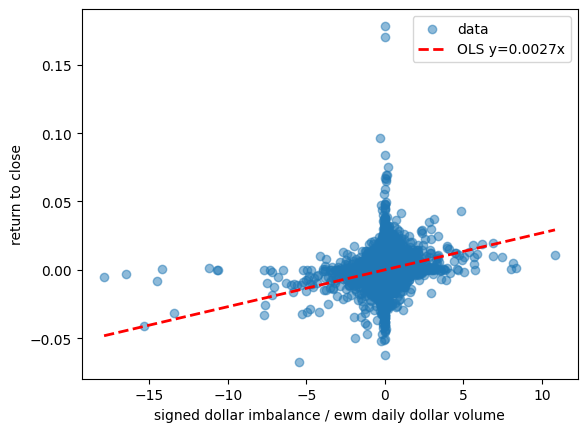

In [5]:
xs = np.linspace(np.min(X), np.max(X))
plt.scatter(X, y, alpha=0.5, label="data")
plt.plot(xs, res.params[0] * xs, label=f'OLS y={res.params[0]:,.4f}x', color='red', linestyle='--', linewidth=2)
plt.xlabel("signed dollar imbalance / ewm daily dollar volume")
plt.ylabel("return to close")
plt.legend()
plt.show()

In [6]:
from scipy.stats import spearmanr

ic, pval = spearmanr(X, y)
print(f"Spearman IC for ewm daily dollar volume: {ic:,.3f} with p-value: {pval:,.3f}")

Spearman IC for ewm daily dollar volume: 0.209 with p-value: 0.000


## Risk (Covariance) Model
Starting with a **SIMPLE** sample covariance of daily returns, filling null daily returns with the symbols **MEAN**.

Very much not a good enough covariance matrix yet. Need shrinkage or a factor model.

In [7]:
# daily_ret = (
#     df_trades
#     .select(["ts_event", "symbol", "price"])
#     .with_columns(pl.col("ts_event").dt.date().alias("date"))
#     .group_by(["date", "symbol"])
#     .agg(
#         pl.col("price").last()
#     )
#     .sort("date")
#     .with_columns(
#         pl.col("price").pct_change().over("symbol").alias("ret")
#     )
#     .pivot(
#         on="symbol",
#         on_columns=UNIVERSE,
#         index="date",
#         values="ret"
#     )
#     .with_columns(pl.all().exclude("date").fill_null(strategy="mean"))
#     .with_columns(pl.all().exclude("date").fill_null(0.0))   # dead names (no trades all window) stay all-null after mean; zero them
# )

# daily_ret = daily_ret.collect(engine="streaming")
# daily_ret

## Daily MVO Optimizer

In [8]:
import cvxpy as cp
import scipy

class ForecastModel:
    """Maps a day's features -> dense alpha vector aligned to `universe`. Missing names -> 0."""
    def __init__(self, universe, beta_1):
        self.universe = universe
        self.sym_idx_map = {s: i for i, s in enumerate(universe)}
        self.beta_1 = beta_1
    
    def get_alpha(self, day_df: pl.DataFrame) -> np.ndarray:
        """Gets the forecast mean return using beta_1. Does not include an intercept, so that 0 signal gets 0 forecast."""
        alpha = np.zeros(len(self.universe))
        for symbol, signal in zip(day_df['symbol'], day_df["signed_mean_imb_ratio"]):
            alpha[self.sym_idx_map[symbol]] = self.beta_1 * signal
        return alpha

class CostModel:
    """Half-spread (in return space) per name; names with no quote -> large cost so the optimizer avoids them."""
    def __init__(self, universe: list):
        self.universe = universe
        self.sym_idx_map = {s:i for i, s in enumerate(universe)}
    
    def get_cost(self, day_df: pl.DataFrame, commission: float) -> np.ndarray:
        cost = np.zeros(len(self.universe))
        for symbol, spread, comm_rate in zip(day_df["symbol"], day_df["spread_return"], commission / day_df['entry_price']):
            cost[self.sym_idx_map[symbol]] = (spread * 0.5) + (2 * comm_rate)
        return cost

class Optimizer:
    """Single-Period Daily MVO system."""
    def __init__(self, universe: list):
        self.universe = universe
        self.N = len(universe)
        
    def set_problem(self, Sigma_r, Sigma_f, Loadings, eps_diag, lam, vol_cap):
        self.p     = cp.Variable(self.N)
        self.alpha = cp.Parameter(self.N)
        self.cost  = cp.Parameter(self.N, nonneg=True)
        self.Sigma_r = cp.Constant(Sigma_r)
        self.L = cp.Constant(Loadings)
        self.eps_diag = eps_diag
        
        self.objective = cp.Maximize(
            self.alpha @ self.p
            - (lam / 2) * cp.quad_form(self.p, Sigma_r)
            - (self.cost / 2) @ cp.abs(self.p)
        )

        Sigma_f_sqrt = scipy.linalg.sqrtm(Sigma_f).real
        D_sqrt  = np.sqrt(self.eps_diag)
        quad_risk = cp.norm(cp.hstack([Sigma_f_sqrt @ self.L @ self.p, cp.multiply(D_sqrt, self.p)]), 2)   # = √(wᵀΣw) but sparse with factors
        self.constraints = [
            self.p @ Loadings[0,:] == 0,    # market neutrality
            cp.sum(self.p) == 0,            # dollar neutrality
            quad_risk <= vol_cap,           # √(wᵀΣw) ≤ target daily dollar volatility
        ]
        
        self.problem = cp.Problem(self.objective, self.constraints)

    def solve(self, alpha, cost) -> np.ndarray:
        self.alpha.value = alpha
        self.cost.value  = cost
        self.problem.solve(warm_start=True, solver="CLARABEL")
        if self.problem.status not in ("optimal", "optimal_inaccurate"):
            raise RuntimeError(self.problem.status)
        return self.p.value                                # optimal dollar portfolio

## Parallel daily solve

Each trading day is an independent QP (the book is flat at every close), so the days fan out across processes with `joblib`'s `loky` backend (works with notebook-defined classes via cloudpickle). Each worker compiles the parametrized problem **once** and warm-starts through a contiguous chunk of days — so compile cost is paid `N_JOBS` times, not once per day. Produces `weights` in the same `{date: {symbol: w}}` shape as the serial loop, so the over-time plot above works unchanged: run this cell, then re-run the plot.

In [9]:
L = np.load("../covariance/loadings.npy")
F = np.load("../covariance/factor_returns.npy")
EPS_DIAG = np.load("../covariance/idiosyncratic_diag_vec.npy")
SIGMA_F = np.load("../covariance/factor_cov_matrix.npy")
SIGMA_R = np.load("../covariance/cov_matrix.npy")

f_model = ForecastModel(UNIVERSE, beta_1 = res.params[0])
c_model = CostModel(UNIVERSE)

In [ ]:
# --- Parallel daily solve (days are independent; book is flat at every close) ---
# Fans the days across processes. Each worker compiles the parametrized QP ONCE
# and warm-starts through a contiguous chunk of days. Produces `weights` in the
# same {date: {symbol: w}} shape as the serial loop, so the over-time plot works
# unchanged. Run AFTER f_model / c_model / SYMBOLS / cov_matrix are defined.
import os
from joblib import Parallel, delayed

N_JOBS = max(1, os.cpu_count() - 2)
COMMISSION_PER_SHARE = 0.0035
LAMBDA = 1e-9                                  # Risk aversion per dollar, ~ 1 / capital.
DAILY_DOLLAR_VOL_CAP = 6_300_000               # 0.0063 * intended capital amount=> annual vol 10%. Real dollar pnl is 0.02 * cap.

def _solve_chunk(symbols, Sigma_r, Sigma_f, Loadings, eps_diag, lam, vol_cap, day_records):
    """One worker: compile the QP once, then warm-start through its chunk of days."""
    opt = Optimizer(symbols)
    opt.set_problem(Sigma_r=Sigma_r, Sigma_f=Sigma_f, Loadings=Loadings, eps_diag=EPS_DIAG, lam=lam, vol_cap=vol_cap)        # compile paid once per worker, not per day
    return [(date, opt.solve(alpha, cost)) for date, alpha, cost in day_records]

def _split_contiguous(items, n):
    """Contiguous chunks so adjacent days share a worker -> warm_start actually helps."""
    k, m = divmod(len(items), n)
    return [items[i * k + min(i, m):(i + 1) * k + min(i + 1, m)] for i in range(n)]

# Build per-day (alpha, cost) in the parent (cheap, vectorized) so workers receive
# only small 1-D arrays; cov_matrix is auto-memmapped by loky and shared read-only.
all_dates = data["date"].unique().sort().to_list()
day_records = [
    (d, f_model.get_alpha(day), c_model.get_cost(day, COMMISSION_PER_SHARE))
    for d in all_dates
    for day in [data.filter(pl.col("date") == d)]
]

chunks = [c for c in _split_contiguous(day_records, N_JOBS) if c]
chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
    delayed(_solve_chunk)(UNIVERSE, SIGMA_R, SIGMA_F, L, EPS_DIAG, LAMBDA, DAILY_DOLLAR_VOL_CAP, chunk) for chunk in chunks
)

weights = {d: dict(zip(UNIVERSE, ws)) for chunk in chunk_results for d, ws in chunk}
print(f"solved {len(weights)} days across {len(chunks)} workers")

### Plotting / Accounting

In [ ]:
# Optimizer weights over time, one line per symbol (only names ever held)
dates = sorted(weights.keys())

held = sorted({s for d in dates for s, wv in weights[d].items()})

fig, ax = plt.subplots(figsize=(16, 8))
for s in held:
    series = [weights[d].get(s, 0.0) for d in dates]
    ax.plot(dates, series, lw=0.8, alpha=0.7)

ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("date")
ax.set_ylabel("weight")
ax.set_title(f"Optimizer weights over time — {len(held)} names")
fig.tight_layout()
plt.show()

In [ ]:
# Scatter weights vs day features over the FULL dataset (all dates pooled)
# Flatten {date: {symbol: w}} -> long frame, then join each day's features from `data`.
w_long = pl.DataFrame(
    {
        "date": [d for d in weights for _ in weights[d]],
        "symbol": [s for d in weights for s in weights[d]],
        "weight": [wv for d in weights for wv in weights[d].values()],
    }
).with_columns(pl.col("symbol").cast(pl.Categorical))

plot_df = data.join(w_long, on=["date", "symbol"], how="inner")

weights_arr = plot_df["weight"].to_numpy()
features = ["dollar_imbalance", "ADV", "signed_mean_imb_ratio"]
log_x = {"dollar_imbalance", "ADV"}   # positive, span orders of magnitude; signed ratio stays linear

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feat in zip(axes, features):
    if feat == "signed_mean_imb_ratio":
        x = plot_df[feat].clip(-1,1).to_numpy()
    else:
        x = plot_df[feat].to_numpy()
    ax.scatter(x, weights_arr, alpha=0.3, s=8)
    ax.axhline(0, color="grey", lw=0.5)
    if feat in log_x:
        ax.set_xscale("log")
    ax.set_xlabel(feat)
    ax.set_ylabel("weight")
    ax.set_title(f"weight vs {feat}")

fig.suptitle(f"Optimizer weights vs features — full dataset ({len(weights)} days, {len(plot_df):,} points)")
fig.tight_layout()
plt.show()

In [ ]:
# ===== Strategy PnL: dollar positions . returns-to-close, net of costs =====
# `weights` is the optimizer's ABSOLUTE-DOLLAR book per day: {date: {symbol: $ position}}.
# Daily gross PnL = sum_i (dollar position_i) * (return from entry to the closing auction_i).
# Costs charged as a dot product  |$pos| . cost_rate:
#   - spread:     HALF the quoted spread, ENTRY only (the auction exit has no spread).
#   - commission: $0.0035/share on BOTH legs; spread_return already bundles 0.0035/price (one leg).
ANN = 252


# Flatten {date: {symbol: $pos}} -> long, then join the day's prices/spread from `data`.
pos_long = pl.DataFrame({
    "date":       [d for d in weights for _ in weights[d]],
    "symbol":     [s for d in weights for s in weights[d]],
    "dollar_pos": [w for d in weights for w in weights[d].values()],
}).with_columns(pl.col("symbol").cast(pl.Categorical))

pnl_daily = (
    data
    .join(pos_long, on=["date", "symbol"], how="inner")
    .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
    .with_columns(
        (pl.col("dollar_pos") * pl.col("ret_to_close")).alias("gross_pnl"),                       # $pos . return
        (COMMISSION_PER_SHARE / pl.col("entry_price")).alias("comm_rate"),                        # per-leg commission, as a return
    )
    # spread_return is the pure quoted spread (ask-bid)/mid. Charge half the spread (cross ONCE
    # on entry; the auction exit has no spread) + commission on BOTH legs.
    .with_columns(
        (0.5 * pl.col("spread_return") + 2.0 * pl.col("comm_rate"))
            .clip(lower_bound=0.0).alias("cost_rate"),
    )
    .with_columns(
        (pl.col("dollar_pos").abs() * pl.col("cost_rate")).alias("cost"),                         # dot product: |$pos| . cost_rate
        (pl.col("gross_pnl") - pl.col("dollar_pos").abs() * pl.col("cost_rate")).alias("net_pnl_name"),
    )
    .group_by("date")
    .agg(
        pl.col("net_pnl_name").sum().alias("net_pnl"),
        pl.col("gross_pnl").sum().alias("gross_pnl"),
        pl.col("cost").sum().alias("cost"),
        pl.col("dollar_pos").abs().sum().alias("gross"),         # gross book deployed that day
    )
    .sort("date")
    .with_columns(pl.col("net_pnl").cum_sum().alias("cum_pnl"))
)

# ----- stats -----
pnl  = pnl_daily["net_pnl"].to_numpy()
cum_pnl  = pnl_daily["cum_pnl"].to_numpy()
mean_gmv = pnl_daily["gross"].mean()                  # FIXED capital base = avg gross book

sharpe  = pnl.mean() / pnl.std(ddof=1) * np.sqrt(ANN)
ann_ret = pnl.mean() * ANN
ann_vol = (pnl / mean_gmv).std(ddof=1) * np.sqrt(ANN)

print(f"Days traded:        {len(pnl)}")
print(f"Avg GMV:            ${mean_gmv:,.0f}")
print(f"Gross PnL:          ${pnl_daily['gross_pnl'].sum():,.0f}")
print(f"Total cost:         ${pnl_daily['cost'].sum():,.0f}")
print(f"Total net PnL:      ${pnl.sum():,.0f}")
print(f"Ann. PnL volatility:    {ann_vol:.2%}")
print(f"Sharpe (ann):       {sharpe:.2f}")
print(f"Daily hit rate:     {(pnl > 0).mean():.1%}")

# ----- plots: cumulative PnL, daily PnL, drawdown, gross book -----
dts   = pnl_daily["date"].to_list()
gross = pnl_daily["gross"].to_numpy()
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 12), sharex=True, height_ratios=[3, 2, 1])

ax1.plot(dts, cum_pnl, color="tab:blue")
ax1.axhline(0, color="grey", lw=0.5)
ax1.set_ylabel("cumulative net PnL ($)")
ax1.set_title(f"Strategy PnL net of costs (positions . returns-to-close) - Sharpe {sharpe:.2f}")

ax2.bar(dts, pnl, color=np.where(pnl >= 0, "tab:green", "tab:red"), width=1.0)
ax2.axhline(0, color="grey", lw=0.5)
ax2.set_ylabel("daily net PnL ($)")

ax3.plot(dts, gross, color="tab:purple")
ax3.axhline(mean_gmv, color="grey", lw=0.8, ls="--", label=f"mean = ${mean_gmv:,.0f}")
ax3.set_ylabel("gross book ($)")
ax3.set_xlabel("date")
ax3.legend(loc="upper left", fontsize=8)

fig.tight_layout()
plt.show()

pnl_daily

#### Some diagnostics

In [ ]:
from scipy.stats import pearsonr, spearmanr
r, pval = spearmanr(pnl_daily["gross"], pnl_daily["cum_pnl"])
r

In [ ]:
# Measuring the sqrt(p.T Sigma_r p) volatility to see the cap.
vols = [
    np.sqrt(pos_long.filter(pl.col("date")==d)['dollar_pos'].to_numpy().T @ SIGMA_R @ pos_long.filter(pl.col("date")==d)['dollar_pos'].to_numpy())
      for d in pos_long['date'].unique()
]

vols

### Parameter Sweeps

In [ ]:
# Two independent 1-D parameter sweeps -> GMV (avg gross book = mean_t sum_i |$pos_{i,t}|).
# Each grid point re-solves EVERY day's QP, reusing the already-built `day_records`,
# `_solve_chunk`, `_split_contiguous` and the loaded covariance pieces from the parallel
# solve above. One parameter varies; the other is held at its baseline (LAMBDA /
# DAILY_DOLLAR_VOL_CAP). Run AFTER the parallel-solve cell (it defines those names).

def _avg_gmv(lam, vol_cap):
    """Solve all days at (lam, vol_cap); return mean daily GMV = mean_t( sum_i |$pos| )."""
    chunks = [c for c in _split_contiguous(day_records, N_JOBS) if c]
    chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
        delayed(_solve_chunk)(UNIVERSE, SIGMA_R, SIGMA_F, L, EPS_DIAG, lam, vol_cap, chunk)
        for chunk in chunks
    )
    gmv_by_day = [np.abs(ws).sum() for chunk in chunk_results for _, ws in chunk]
    return float(np.mean(gmv_by_day))

# --- Sweep grids ---
lambda_grid  = np.geomspace(1e-11, 1e-7, 7)             # risk aversion per dollar (~ 1/capital)
vol_cap_grid = np.linspace(1_000_000, 14_000_000, 8)   # daily dollar volatility target

gmv_vs_lambda  = [_avg_gmv(lam, DAILY_DOLLAR_VOL_CAP) for lam in lambda_grid]
gmv_vs_vol_cap = [_avg_gmv(LAMBDA, vc) for vc in vol_cap_grid]

# --- Plots: GMV for each sweep ---
fig, (axL, axV) = plt.subplots(1, 2, figsize=(15, 5))

axL.plot(lambda_grid, gmv_vs_lambda, marker="o")
axL.axvline(LAMBDA, color="grey", ls="--", lw=0.8, label=f"baseline λ = {LAMBDA:g}")
axL.set_xscale("log")
axL.set_xlabel("λ  (risk aversion per dollar)")
axL.set_ylabel("avg GMV ($)")
axL.set_title(f"GMV vs λ   (vol cap = ${DAILY_DOLLAR_VOL_CAP:,.0f})")
axL.legend(fontsize=8)

axV.plot(vol_cap_grid, gmv_vs_vol_cap, marker="o", color="tab:orange")
axV.axvline(DAILY_DOLLAR_VOL_CAP, color="grey", ls="--", lw=0.8, label=f"baseline cap = ${DAILY_DOLLAR_VOL_CAP:,.0f}")
axV.set_xlabel("daily dollar vol cap ($)")
axV.set_ylabel("avg GMV ($)")
axV.set_title(f"GMV vs daily vol cap   (λ = {LAMBDA:g})")
axV.legend(fontsize=8)

fig.tight_layout()
plt.show()

### Notes
- Risk aversion is generally ~ 1/CAPITAL, within a factor of 2. Then GMV is is abs sum of positions. Each position is then in $ units.
- Assumption to get on wtih life with best-k approx: idiosyncratic covariance/variance error is evenly distributed over assets
        (assuming theres the cov matrix, and then a per asset volatility error on teh diagonal).
        - GARCH(1,1) on the diagonal error epsilon (D) that is time varying and the factor covariance doesn't capture.
- Market neutrality: get loadings and constrain that P dot L is 0.
- Better than PCA is a random matrix theory/eigenvalue clipping work
- Generalized alpha trick: think about operators. Think about a cross-sectionalized operator.
